# Onde está o faturamento de 2025?
**Análise para a diretoria comercial — por região, por mês e por canal de venda**

**Pergunta:** onde concentrar o esforço comercial em 2026?
**Base:** `dados/vendas.csv` — 5.000 vendas de 01/01/2025 a 31/12/2025.
**Faturamento** = quantidade × preço unitário.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.options.display.float_format = '{:,.2f}'.format
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.titlesize': 12})
COR, COR_DESTAQUE, COR_NEUTRA = '#9bb7d4', '#1f4e79', '#c9c9c9'

def mi(v):  # R$ em milhões, formato brasileiro
    return f"R$ {v/1e6:,.1f} mi".replace(',', 'X').replace('.', ',').replace('X', '.')

d = pd.read_csv('dados/vendas.csv', parse_dates=['data'])
d['faturamento'] = d['quantidade'] * d['preco_unitario']
d['custo'] = d['quantidade'] * d['custo_unitario']
d['mes'] = d['data'].dt.month
d.head()

,data,produto,categoria,regiao,quantidade,preco_unitario,custo_unitario,canal_venda,faturamento,custo,mes
0,2025-01-01,Mouse,Acessórios,Centro-Oeste,5,52.97,30.53,Online,264.85,152.65,1
1,2025-01-01,Monitor,Eletrônicos,Sul,7,"1,118.13",765.68,Loja física,"7,826.91","5,359.76",1
2,2025-01-01,Tablet,Eletrônicos,Centro-Oeste,6,"1,611.59",959.28,Marketplace,"9,669.54","5,755.68",1
3,2025-01-01,Monitor,Eletrônicos,Nordeste,4,953.18,559.37,Loja física,"3,812.72","2,237.48",1
4,2025-01-01,Teclado,Acessórios,Sul,6,174.44,124.57,Online,"1,046.64",747.42,1


## 1. Qualidade dos dados
Antes de somar, conferimos se a base é confiável.

In [2]:
print('Linhas:', len(d), '| Duplicadas:', d.duplicated().sum())
print('Período:', d['data'].min().date(), 'a', d['data'].max().date())
print('Quantidade < 1 ou preço/custo <= 0:', ((d.quantidade < 1) | (d.preco_unitario <= 0) | (d.custo_unitario <= 0)).sum())
print('Vendas com custo acima do preço:', (d.custo_unitario > d.preco_unitario).sum())
print()
print('Valores vazios por coluna:')
print(d.isna().sum()[lambda s: s > 0])
sem_reg = d[d['regiao'].isna()]
print(f"\nVendas sem região: {len(sem_reg)} ({len(sem_reg)/len(d):.1%} das linhas) = {mi(sem_reg.faturamento.sum())} "
      f"({sem_reg.faturamento.sum()/d.faturamento.sum():.1%} do faturamento)")

Linhas: 5000 | Duplicadas: 0
Período: 2025-01-01 a 2025-12-31
Quantidade < 1 ou preço/custo <= 0: 0
Vendas com custo acima do preço: 0

Valores vazios por coluna:
regiao    154
dtype: int64

Vendas sem região: 154 (3.1% das linhas) = R$ 0,7 mi (2.9% do faturamento)


**Único problema encontrado:** 154 vendas estão sem região (≈ 2,9% do faturamento). Não vamos descartá-las nem chutar a região: elas entram nos totais de mês e de canal e aparecem como **"Não informada"** na visão por região. Como são poucas, não mudam nenhuma conclusão — mas vale pedir ao time de vendas que preencha a região no cadastro.

In [3]:
d['regiao'] = d['regiao'].fillna('Não informada')
total = d['faturamento'].sum()
print('Faturamento total 2025:', mi(total))
print('Nº de vendas:', f"{len(d):,}".replace(',', '.'), '| Ticket médio por venda:', f"R$ {d.faturamento.mean():,.0f}".replace(',', '.'))
print('Margem bruta (faturamento - custo):', f"{1 - d.custo.sum()/total:.1%}")

Faturamento total 2025: R$ 25,0 mi
Nº de vendas: 5.000 | Ticket médio por venda: R$ 5.003
Margem bruta (faturamento - custo): 36.3%


## 2. Por região

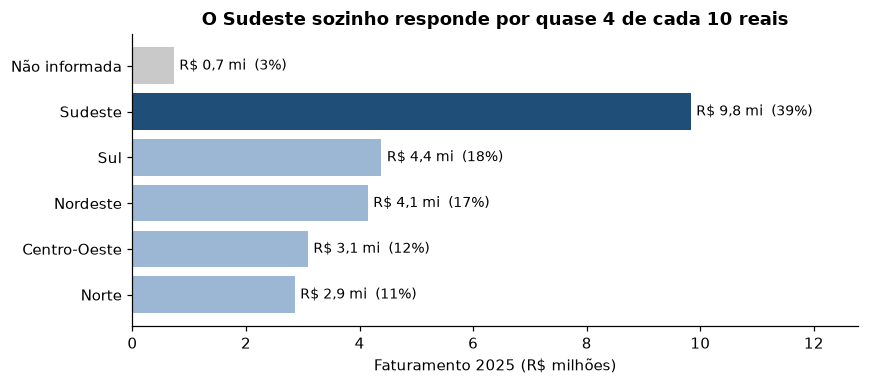

,Faturamento (R$),% do total
regiao,,
Sudeste,"9,827,937.32",39.29
Sul,"4,380,944.08",17.51
Nordeste,"4,140,642.33",16.55
Centro-Oeste,"3,086,274.60",12.34
Norte,"2,854,711.86",11.41
Não informada,"725,629.43",2.90


In [4]:
reg = d.groupby('regiao')['faturamento'].sum()
ordem = reg.drop('Não informada').sort_values().index.tolist() + ['Não informada']
reg = reg[ordem]

fig, ax = plt.subplots(figsize=(8, 3.6))
cores = [COR_DESTAQUE if r == 'Sudeste' else COR_NEUTRA if r == 'Não informada' else COR for r in reg.index]
ax.barh(reg.index, reg.values / 1e6, color=cores)
for i, v in enumerate(reg.values):
    ax.text(v/1e6 + 0.1, i, f"{mi(v)}  ({v/total:.0%})", va='center', fontsize=9)
ax.set_xlim(0, reg.max()/1e6 * 1.3); ax.set_xlabel('Faturamento 2025 (R$ milhões)')
ax.set_title('O Sudeste sozinho responde por quase 4 de cada 10 reais')
plt.tight_layout(); plt.show()

tab = reg.sort_values(ascending=False).to_frame('Faturamento (R$)')
tab['% do total'] = tab.iloc[:, 0] / total * 100
tab

**Leitura:** o Sudeste fatura **mais que o dobro do segundo colocado** (Sul, 2,2x). Sul e Nordeste formam um segundo bloco, e Centro-Oeste e Norte são as menores regiões. A margem bruta é praticamente igual em todas (≈ 36%), então o tamanho do faturamento é o que diferencia as regiões.

## 3. Por mês

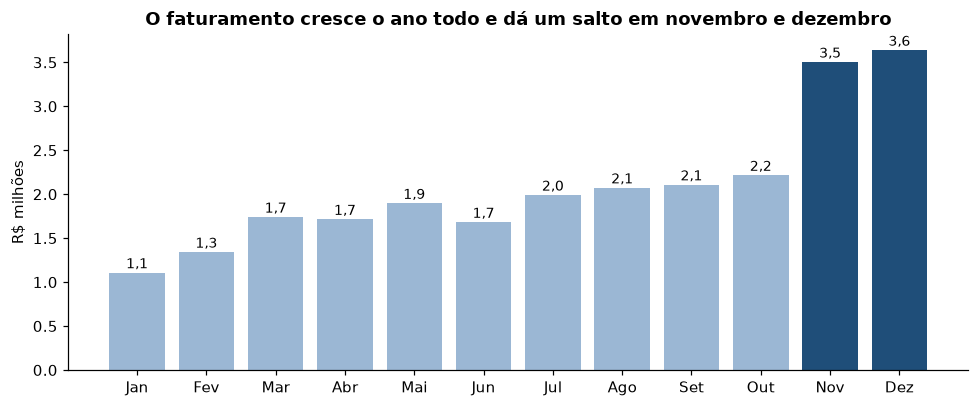

Nov + Dez: R$ 7,1 mi = 29% do ano (2 de 12 meses)
Dezembro vs. janeiro: 3.3x
Novembro vs. outubro: +58%
1º semestre: R$ 9,5 mi | 2º semestre: R$ 15,5 mi


In [5]:
nomes = ['Jan','Fev','Mar','Abr','Mai','Jun','Jul','Ago','Set','Out','Nov','Dez']
mes = d.groupby('mes')['faturamento'].sum()

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(nomes, mes.values / 1e6, color=[COR_DESTAQUE if m >= 11 else COR for m in mes.index])
for i, v in enumerate(mes.values):
    ax.text(i, v/1e6 + 0.05, f"{v/1e6:.1f}".replace('.', ','), ha='center', fontsize=9)
ax.set_ylabel('R$ milhões'); ax.set_title('O faturamento cresce o ano todo e dá um salto em novembro e dezembro')
plt.tight_layout(); plt.show()

nd = mes[[11, 12]].sum()
print(f"Nov + Dez: {mi(nd)} = {nd/total:.0%} do ano (2 de 12 meses)")
print(f"Dezembro vs. janeiro: {mes[12]/mes[1]:.1f}x")
print(f"Novembro vs. outubro: {mes[11]/mes[10]-1:+.0%}")
print(f"1º semestre: {mi(mes[:6].sum())} | 2º semestre: {mi(mes[6:].sum())}")

**O que está por trás do salto de fim de ano?** Vale checar se é mais vendas ou vendas maiores.

In [6]:
m = d.groupby('mes').agg(vendas=('faturamento', 'size'), ticket_medio=('faturamento', 'mean'))
m.index = nomes
m.T.round(0)

,Jan,Fev,Mar,Abr,Mai,Jun,Jul,Ago,Set,Out,Nov,Dez
vendas,243.00,249.00,362.00,335.00,393.00,358.00,383.00,435.00,411.00,432.00,654.00,745.00
ticket_medio,"4,560.00","5,389.00","4,808.00","5,120.00","4,826.00","4,698.00","5,199.00","4,767.00","5,129.00","5,131.00","5,357.00","4,884.00"


O ticket médio fica estável (cerca de R$ 5 mil) o ano inteiro; **o que cresce é o número de vendas** (de ~245 em jan/fev para ~650–750 em nov/dez). Ou seja: o fim de ano vende mais, não vende mais caro.

⚠️ **Limite desta análise:** só temos 2025. O faturamento já vinha subindo de janeiro a outubro, então não dá para separar quanto do salto de nov/dez é *sazonalidade* (todo ano é assim) e quanto é *tendência de crescimento* do negócio. Com 2024 na mão, essa dúvida se resolve.

## 4. Por canal de venda

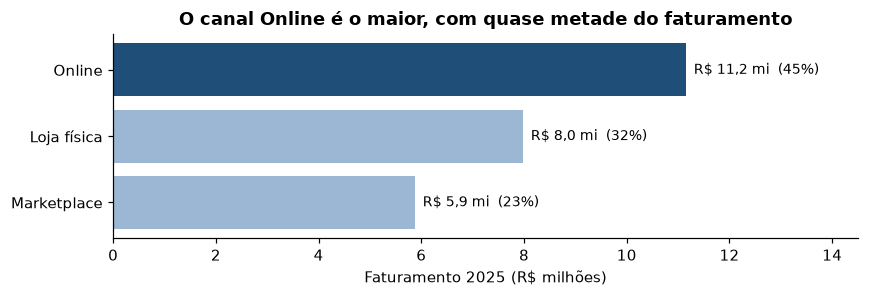

In [7]:
can = d.groupby('canal_venda')['faturamento'].sum().sort_values()
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.barh(can.index, can.values / 1e6, color=[COR_DESTAQUE if c == 'Online' else COR for c in can.index])
for i, v in enumerate(can.values):
    ax.text(v/1e6 + 0.15, i, f"{mi(v)}  ({v/total:.0%})", va='center', fontsize=9)
ax.set_xlim(0, can.max()/1e6 * 1.3); ax.set_xlabel('Faturamento 2025 (R$ milhões)')
ax.set_title('O canal Online é o maior, com quase metade do faturamento')
plt.tight_layout(); plt.show()

**Leitura:** Online lidera, Loja física vem em segundo e Marketplace é o menor. A margem bruta também é a mesma nos três canais (≈ 36%): nenhum canal "paga melhor" por real vendido.

## 5. Região × canal × mês: onde estão as concentrações

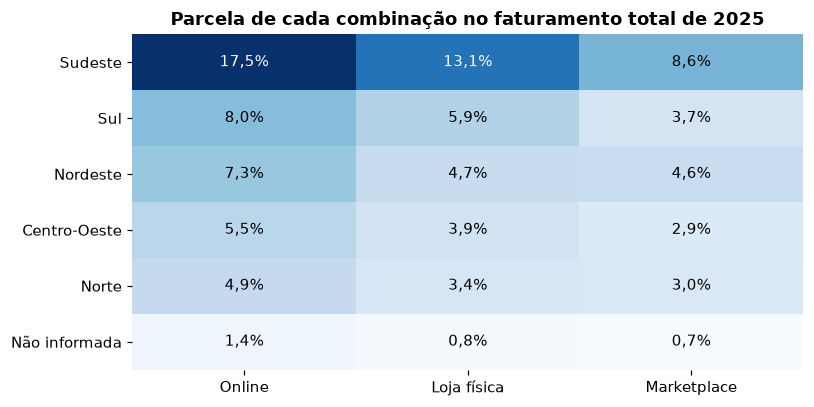

Sudeste + Online: R$ 4,4 mi (17.5% do total)
Sudeste (3 canais): 39.3% | Online (todas as regiões): 44.6%


In [8]:
cruz = d.pivot_table(index='regiao', columns='canal_venda', values='faturamento', aggfunc='sum')
cruz = cruz[['Online', 'Loja física', 'Marketplace']]
ordem = cruz.drop('Não informada').sum(axis=1).sort_values(ascending=False).index.tolist() + ['Não informada']
cruz = cruz.loc[ordem]
pct = cruz / total * 100

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.imshow(pct.values, cmap='Blues', aspect='auto')
ax.set_xticks(range(3), pct.columns); ax.set_yticks(range(len(pct)), pct.index)
for i in range(pct.shape[0]):
    for j in range(pct.shape[1]):
        v = pct.values[i, j]
        ax.text(j, i, f"{v:.1f}%".replace('.', ','), ha='center', va='center', color='white' if v > 10 else 'black')
ax.set_title('Parcela de cada combinação no faturamento total de 2025')
for s in ax.spines.values(): s.set_visible(False)
plt.tight_layout(); plt.show()

print('Sudeste + Online:', mi(cruz.loc['Sudeste', 'Online']), f"({cruz.loc['Sudeste','Online']/total:.1%} do total)")
print('Sudeste (3 canais):', f"{cruz.loc['Sudeste'].sum()/total:.1%}", '| Online (todas as regiões):', f"{cruz['Online'].sum()/total:.1%}")

Em todas as regiões o desenho é o mesmo: Online primeiro, Loja física depois, Marketplace por último. A região muda o *tamanho*, não o *perfil de canal*. A maior célula isolada é **Sudeste + Online (~17,5% do faturamento)**.

Agora, o fim de ano: quais regiões e canais mais dependeram de nov/dez?

In [9]:
d['periodo'] = d['mes'].map(lambda x: 'Nov-Dez' if x >= 11 else 'Jan-Out')
def peso_fim_ano(col):
    t = d.pivot_table(index=col, columns='periodo', values='faturamento', aggfunc='sum')
    t['% do ano vendido em Nov-Dez'] = t['Nov-Dez'] / (t['Nov-Dez'] + t['Jan-Out']) * 100
    return t.sort_values('% do ano vendido em Nov-Dez', ascending=False)
print('Por região'); display(peso_fim_ano('regiao').round(1))
print('Por canal');  display(peso_fim_ano('canal_venda').round(1))

Por região


periodo,Jan-Out,Nov-Dez,% do ano vendido em Nov-Dez
regiao,,,
Não informada,"473,077.50","252,552.00",34.80
Centro-Oeste,"2,149,033.30","937,241.30",30.40
Sudeste,"6,857,492.90","2,970,444.40",30.20
Nordeste,"2,995,332.40","1,145,309.90",27.70
Norte,"2,085,403.30","769,308.60",26.90
Sul,"3,313,477.90","1,067,466.20",24.40


Por canal


periodo,Jan-Out,Nov-Dez,% do ano vendido em Nov-Dez
canal_venda,,,
Loja física,"5,579,074.50","2,403,411.90",30.10
Online,"7,939,817.20","3,215,821.40",28.80
Marketplace,"4,354,925.60","1,523,089.00",25.90


Todos os recortes concentram entre ~24% e ~35% do ano em nov/dez (a linha "Não informada" é pequena e oscila mais). Entre as regiões, **Centro-Oeste e Sudeste** são as que mais dependem do fim de ano; o **Sul** é a que menos. Entre os canais, o **Marketplace** é o que menos aproveita o fim de ano. Não é uma diferença enorme, mas indica onde o impulso de fim de ano é mais fraco.

## 6. Conclusão para a diretoria

In [10]:
sud = reg['Sudeste']; onl = can['Online']
top2 = reg.drop('Não informada').sort_values(ascending=False)
print(f"• Sudeste: {mi(sud)} ({sud/total:.0%} do faturamento) — {sud/top2.iloc[1]:.1f}x o segundo colocado ({top2.index[1]}).")
print(f"• Online: {mi(onl)} ({onl/total:.0%}).")
print(f"• Nov+Dez: {nd/total:.0%} do ano em 2 meses.")

• Sudeste: R$ 9,8 mi (39% do faturamento) — 2.2x o segundo colocado (Sul).
• Online: R$ 11,2 mi (45%).
• Nov+Dez: 29% do ano em 2 meses.


### Onde está o faturamento (R$ 25,0 milhões em 2025)

- **Região:** o **Sudeste** concentra **39%** (R$ 9,8 mi), mais que o dobro do Sul (R$ 4,4 mi, 18%) e do Nordeste (R$ 4,1 mi, 17%). Centro-Oeste (R$ 3,1 mi) e Norte (R$ 2,9 mi) somam 24%.
- **Canal:** o **Online** responde por **45%** (R$ 11,2 mi), a Loja física por 32% e o Marketplace por 23%. Esse ranking se repete em todas as regiões.
- **Mês:** o faturamento **cresceu ao longo do ano** (de R$ 1,1 mi em janeiro para R$ 3,6 mi em dezembro) e **novembro e dezembro sozinhos valeram 29% do ano**. O crescimento vem de **mais vendas**, não de vendas maiores.

### Recomendação para 2026
1. **Proteger e expandir o Online no Sudeste** — é a maior combinação (≈ 17,5% do faturamento) e onde cada ponto de melhora pesa mais.
2. **Preparar o fim de ano com antecedência** (estoque, equipe, campanhas): dois meses decidem quase 30% do resultado.
3. **Tratar Sul e Nordeste como a segunda frente de crescimento**: são as regiões de porte intermediário, já com bom volume. Norte e Centro-Oeste ficam como apostas de menor prioridade.
4. **Marketplace**: é o menor canal e o que menos aproveita o fim de ano; só vale reforçar com uma meta clara de retorno.

### O que esta análise *não* diz
- **Margem não ajuda a escolher:** é ≈ 36% em todas as regiões e canais. A prioridade vem do tamanho do faturamento, não da lucratividade.
- **Só há dados de 2025.** Não dá para saber se o Sudeste ou o Online estão *crescendo mais rápido* que os demais, nem se o salto de nov/dez se repete todo ano. Recomenda-se incluir 2024 antes de fechar as metas.
- **2,9% do faturamento (R$ 0,7 mi) está sem região**, o que não altera o ranking, mas deve ser corrigido no cadastro.